## Импорты

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay

# Чтение файла

In [ ]:
data = pd.read_csv('data_2018.csv')
data = data.drop(columns=['int_rate', 'sub_grade', 'installment', 'grade', 'id'])
data.head()

,loan_amnt,term,emp_length,home_ownership,annual_inc,verification_status,purpose,addr_state,application_type,dti,...,num_tl_90g_dpd_24m,num_tl_op_past_12m,num_tl_120dpd_2m,loan_status,issue_d,issue_d_dt,fico,credit_history_years,mths_since_last_delinq_missing,mths_since_recent_inq_missing
0,3000.0,36,9.0,RENT,52000.0,Source Verified,major_purchase,WA,Individual,0.58,...,0.0,1.0,0.0,1,Mar-2018,2018-03-01,762.0,20.2,0,0
1,5000.0,36,10.0,OWN,55000.0,Not Verified,other,GA,Individual,14.18,...,0.0,2.0,0.0,1,Mar-2018,2018-03-01,677.0,16.6,0,0
2,7000.0,36,0.0,MORTGAGE,40000.0,Verified,home_improvement,TX,Individual,20.25,...,0.0,2.0,0.0,1,Mar-2018,2018-03-01,697.0,11.0,0,0
3,30000.0,36,10.0,OWN,57000.0,Verified,debt_consolidation,FL,Individual,27.58,...,0.0,5.0,0.0,1,Mar-2018,2018-03-01,682.0,17.9,0,0
4,21000.0,60,10.0,OWN,85000.0,Source Verified,house,NY,Individual,15.76,...,0.0,4.0,0.0,1,Mar-2018,2018-03-01,667.0,9.3,0,0


# EDA

## Баланс классов

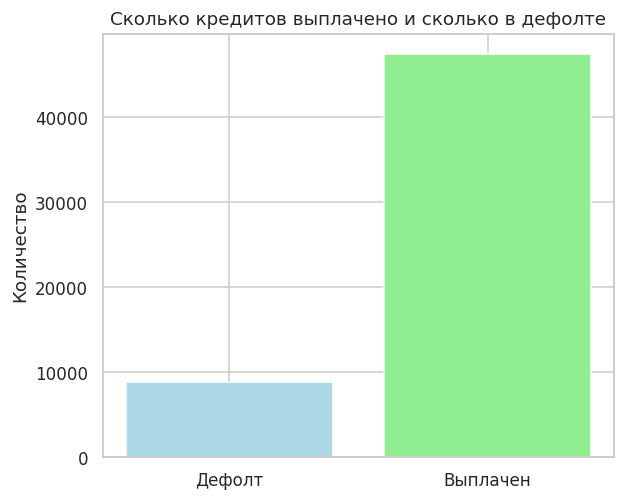

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

counts = data['loan_status'].value_counts()
ax.bar(['Дефолт', 'Выплачен'], [counts[0], counts[1]], color=['lightblue', 'lightgreen'])
ax.set_title('Сколько кредитов выплачено и сколько в дефолте')
ax.set_ylabel('Количество')

plt.show()

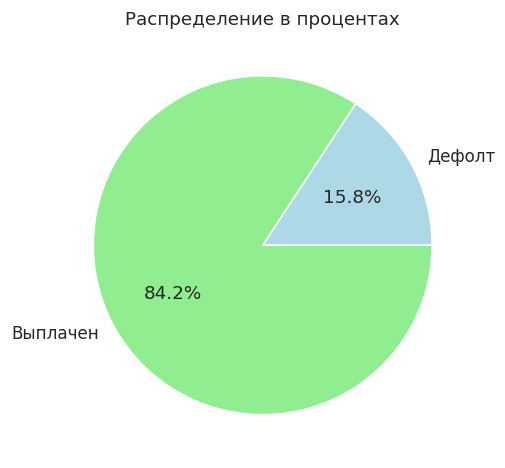

In [ ]:
counts = data['loan_status'].value_counts().sort_index()

plt.figure(figsize=(5, 5))
plt.pie([counts.iloc[0], counts.iloc[1]], labels=['Дефолт', 'Выплачен'],
        colors=['lightblue', 'lightgreen'], autopct='%1.1f%%')
plt.title('Распределение в процентах')
plt.show()

## Числовые признаки для дефолта и выплаченного

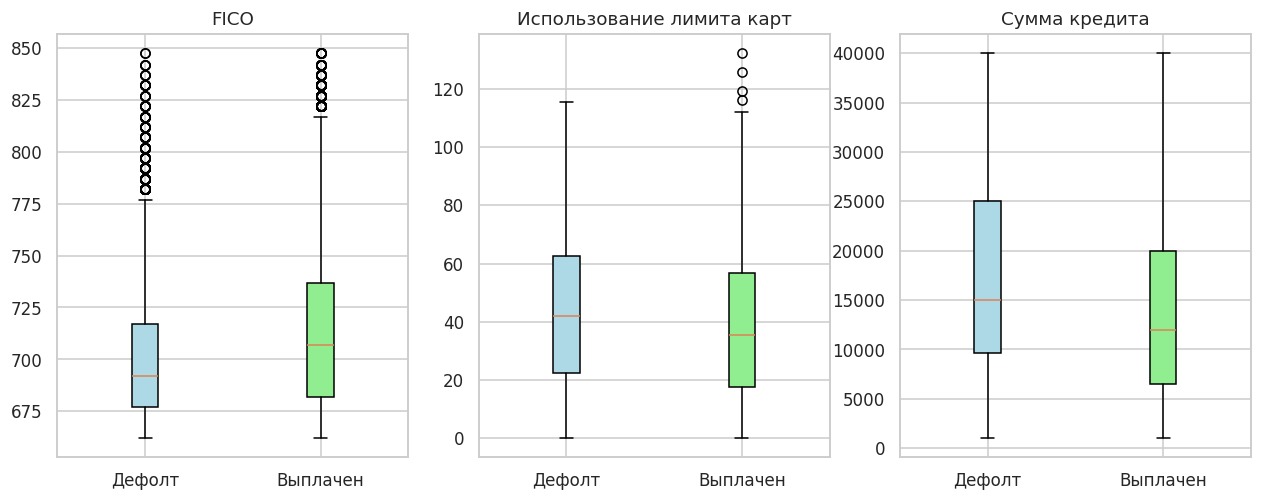

In [ ]:
features = ['fico', 'revol_util', 'loan_amnt']
titles = ['FICO', 'Использование лимита карт', 'Сумма кредита']

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i in range(3):
    group0 = data[data['loan_status'] == 0][features[i]].dropna()
    group1 = data[data['loan_status'] == 1][features[i]].dropna()

    box = axes[i].boxplot([group0, group1], patch_artist=True)
    box['boxes'][0].set_facecolor('lightblue')
    box['boxes'][1].set_facecolor('lightgreen')
    axes[i].set_xticklabels(['Дефолт', 'Выплачен'])
    axes[i].set_title(titles[i])

plt.show()

## Доля дефолтов по категориям

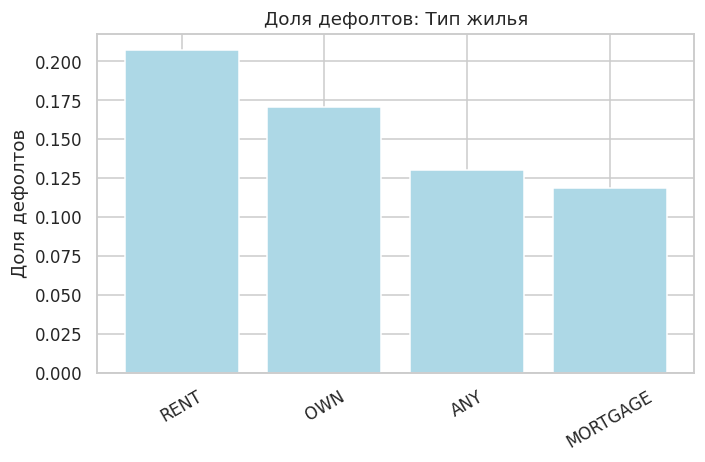

In [ ]:
rate = data.groupby('home_ownership')['loan_status'].apply(lambda x: (x == 0).mean())
rate = rate.sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(rate.index, rate.values, color='lightblue')
plt.title('Доля дефолтов: Тип жилья')
plt.ylabel('Доля дефолтов')
plt.xticks(rotation=30)
plt.show()

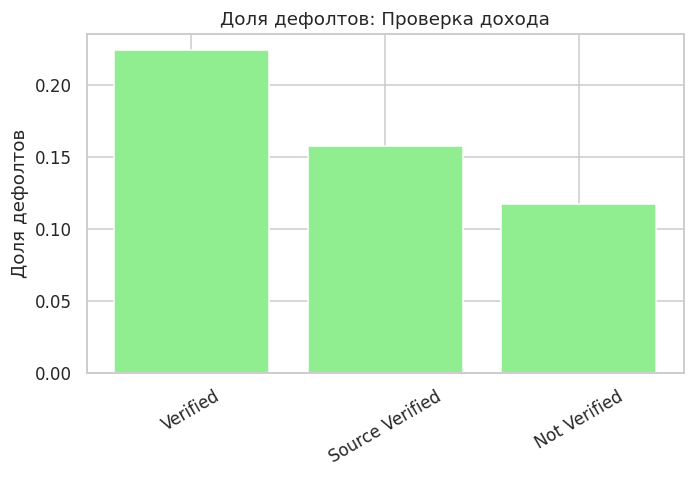

In [ ]:
rate = data.groupby('verification_status')['loan_status'].apply(lambda x: (x == 0).mean())
rate = rate.sort_values(ascending=False)

plt.figure(figsize=(7, 4))
plt.bar(rate.index, rate.values, color='lightgreen')
plt.title('Доля дефолтов: Проверка дохода')
plt.ylabel('Доля дефолтов')
plt.xticks(rotation=30)
plt.show()

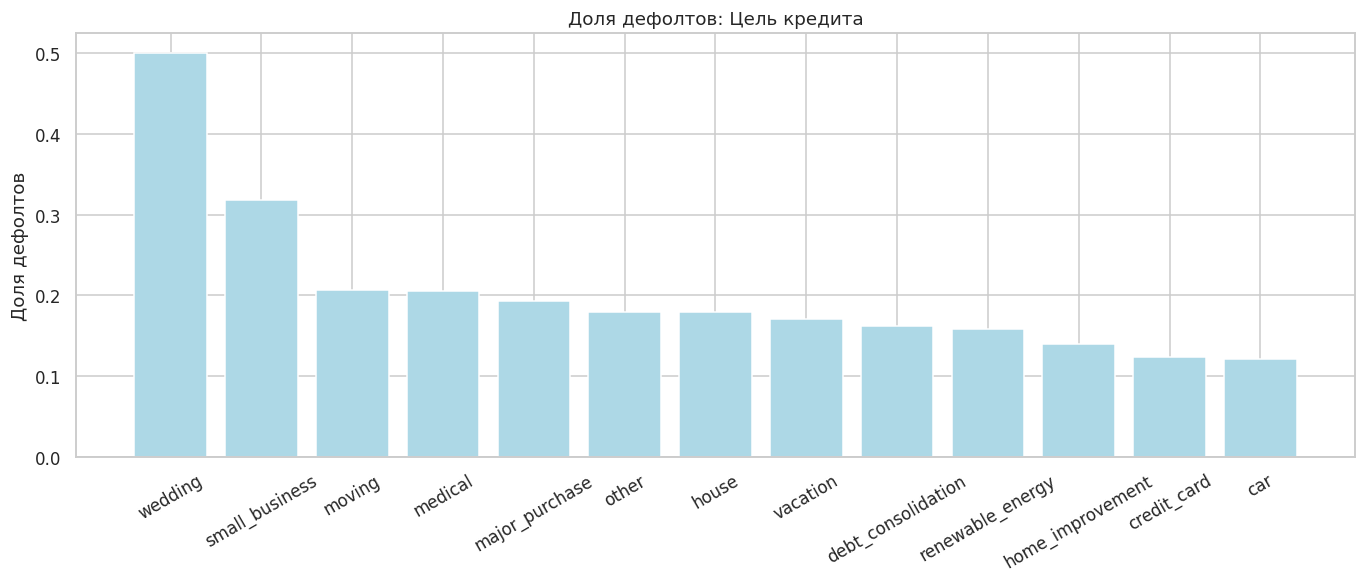

In [ ]:
rate = data.groupby('purpose')['loan_status'].apply(lambda x: (x == 0).mean())
rate = rate.sort_values(ascending=False)

plt.figure(figsize=(15, 5))
plt.bar(rate.index, rate.values, color='lightblue')
plt.title('Доля дефолтов: Цель кредита')
plt.ylabel('Доля дефолтов')
plt.xticks(rotation=30)
plt.show()

## Доля дефолтов по сроку кредита

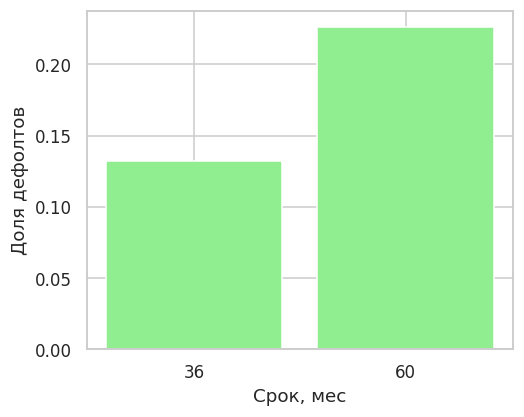

In [ ]:
aaa=data.groupby('term')['loan_status'].apply(lambda x: (x == 0).mean())

plt.figure(figsize=(5, 4))
plt.bar(aaa.index, aaa.values, color='lightgreen', width=20)
plt.ylabel('Доля дефолтов')
plt.xlabel('Срок, мес')
plt.xticks([36, 60])
plt.show()

## Матрица корреляций для основных признаков

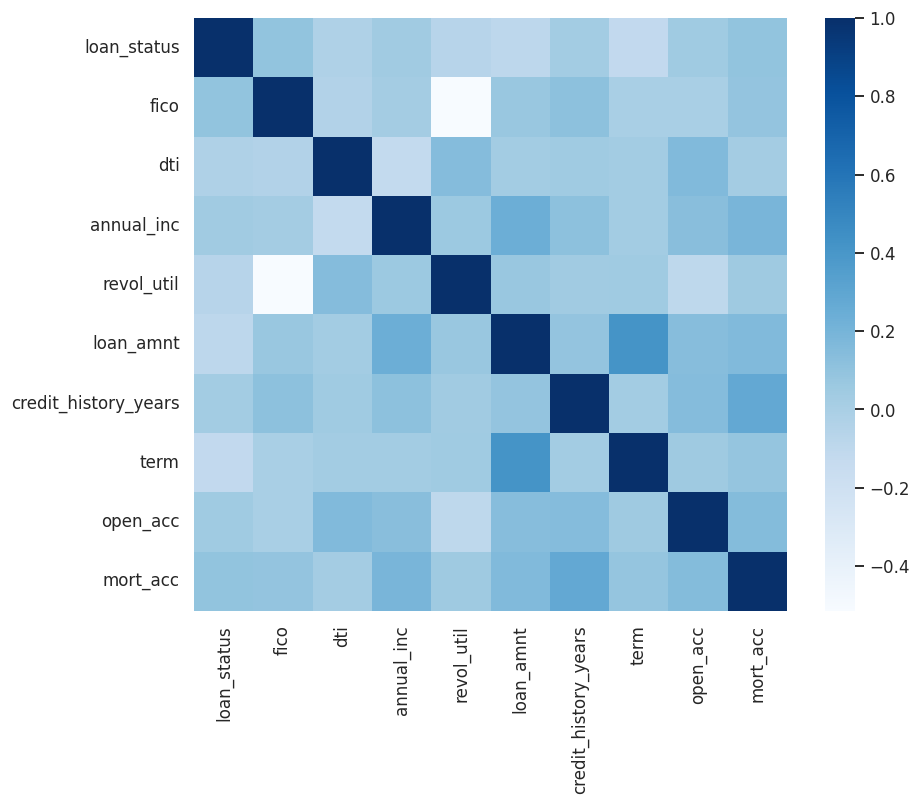

In [ ]:
key_cols = ['loan_status', 'fico', 'dti', 'annual_inc', 'revol_util',
            'loan_amnt', 'credit_history_years', 'term', 'open_acc', 'mort_acc']

corr = data[key_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap='Blues', square=True)
plt.show()

## Чисточка

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

def clean_base(df, drop_dups=False):
    df = df.copy()
    df = df.drop(columns=['issue_d', 'issue_d_dt'], errors='ignore')

    df['mths_since_last_delinq'] = df['mths_since_last_delinq'].fillna(999)
    df['mths_since_recent_inq'] = df['mths_since_recent_inq'].fillna(999)

    if drop_dups:
        dup_drop = ['pub_rec_bankruptcies', 'num_tl_30dpd', 'tot_hi_cred_lim',
                    'num_rev_tl_bal_gt_0', 'num_sats', 'num_op_rev_tl',
                    'total_il_high_credit_limit', 'bc_util', 'total_bc_limit',
                    'mo_sin_old_rev_tl_op', 'num_tl_120dpd_2m']
        df = df.drop(columns=dup_drop, errors='ignore')

    num_cols = [c for c in df.select_dtypes('number').columns if c != 'loan_status']
    imputer = SimpleImputer(strategy='median')
    df[num_cols] = imputer.fit_transform(df[num_cols])

    return df

nominal = ['home_ownership', 'verification_status', 'purpose', 'addr_state', 'application_type']

## Набор для кнн и логрег

In [ ]:
from sklearn.preprocessing import PowerTransformer

df_ksl = clean_base(data, drop_dups=True)

y_ksl = df_ksl['loan_status']
X_ksl = df_ksl.drop(columns=['loan_status', 'id'], errors='ignore')

X_train_ksl, X_test_ksl, y_train_ksl, y_test_ksl = train_test_split(X_ksl, y_ksl, test_size=0.2, random_state=67, stratify=y_ksl)

X_train_ksl = pd.get_dummies(X_train_ksl, columns=nominal, drop_first=True, dtype=int)
X_test_ksl = pd.get_dummies(X_test_ksl, columns=nominal, drop_first=True, dtype=int)
X_test_ksl = X_test_ksl.reindex(columns=X_train_ksl.columns, fill_value=0)

pt = PowerTransformer()
skewed_cols = ['annual_inc', 'revol_bal', 'tot_cur_bal']
X_train_ksl[skewed_cols] = pt.fit_transform(X_train_ksl[skewed_cols])
X_test_ksl[skewed_cols] = pt.transform(X_test_ksl[skewed_cols])

scaler = StandardScaler()
X_train_ksl = pd.DataFrame(scaler.fit_transform(X_train_ksl), columns=X_train_ksl.columns)
X_test_ksl = pd.DataFrame(scaler.transform(X_test_ksl), columns=X_train_ksl.columns)

print('train размер', X_train_ksl.shape)
print('test размер', X_test_ksl.shape)

train размер (45054, 113)
test размер (11264, 113)


## Набор для деревьев и бустинга

In [ ]:
df_dlb = clean_base(data, drop_dups=False)

y_dlb = df_dlb['loan_status']
X_dlb = df_dlb.drop(columns=['loan_status', 'id'], errors='ignore')

X_train_dlb, X_test_dlb, y_train_dlb, y_test_dlb = train_test_split(X_dlb, y_dlb, test_size=0.2, random_state=67, stratify=y_dlb)

X_train_dlb = pd.get_dummies(X_train_dlb, columns=nominal, drop_first=False, dtype=int)
X_test_dlb = pd.get_dummies(X_test_dlb, columns=nominal, drop_first=False, dtype=int)
X_test_dlb = X_test_dlb.reindex(columns=X_train_dlb.columns, fill_value=0)

print('train размер', X_train_dlb.shape)
print('test размер', X_test_dlb.shape)

train размер (45054, 129)
test размер (11264, 129)


ksl для логрег и кнн

dlb для деревьев и бустинга

# Логрег

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, roc_curve

logreg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logreg.fit(X_train_ksl, y_train_ksl)

y_pred = logreg.predict(X_test_ksl)
y_proba = logreg.predict_proba(X_test_ksl)[:, 1]

print('ROC-AUC:', roc_auc_score(y_test_ksl, y_proba))
print(classification_report(y_test_ksl, y_pred, target_names=['Дефолт', 'Выплачен']))

ROC-AUC: 0.7099238109656993
              precision    recall  f1-score   support

      Дефолт       0.26      0.64      0.37      1775
    Выплачен       0.91      0.65      0.76      9489

    accuracy                           0.65     11264
   macro avg       0.58      0.65      0.56     11264
weighted avg       0.80      0.65      0.70     11264



### Матрица ошибок

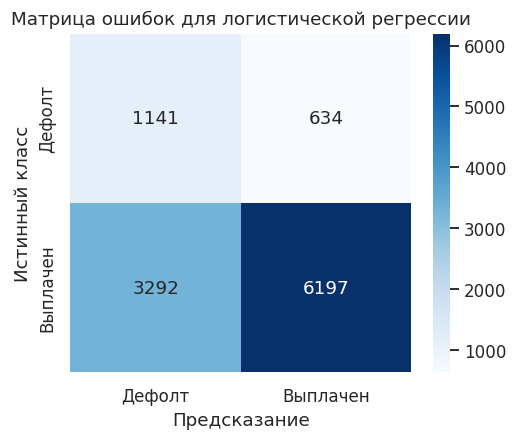

In [ ]:
cm=confusion_matrix(y_test_ksl, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Дефолт', 'Выплачен'], yticklabels=['Дефолт', 'Выплачен'])
plt.xlabel('Предсказание')
plt.ylabel('Истинный класс')
plt.title('Матрица ошибок для логистической регрессии')
plt.show()

### ROC график

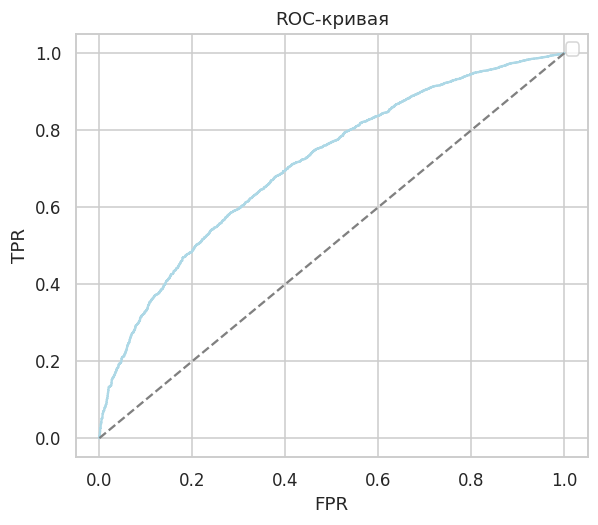

In [ ]:
fpr, tpr, a = roc_curve(y_test_ksl, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='lightblue')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC-кривая')
plt.show()

#KNN

по метрике для подбора: оптимизировать буду по ROC-AUC, а не по accuracy - иначе из-за дисбаланса «лучшим» окажется KNN, который всем ставит «выплачен».

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import average_precision_score

sub = X_train_ksl.sample(12000, random_state=67)
y_sub = y_train_ksl.loc[sub.index]
params = {"n_neighbors": range(53, 100, 2), "weights": ["uniform", "distance"], "p": [1, 2]}
cv = StratifiedKFold(4, shuffle=True, random_state=67)
grid = GridSearchCV(KNeighborsClassifier(), params, scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(sub, y_sub)
print("Лучшие параметры:", grid.best_params_)
print("CV ROC-AUC:", round(grid.best_score_, 3))

knn = grid.best_estimator_.fit(X_train_ksl, y_train_ksl)
proba_knn = knn.predict_proba(X_test_ksl)[:, 1]
pred_knn = knn.predict(X_test_ksl)
print("KNN на тесте:")
print("ROC-AUC:", round(roc_auc_score(y_test_ksl, proba_knn), 3))
print("PR-AUC :", round(average_precision_score(y_test_ksl, proba_knn), 3))
print(classification_report(y_test_ksl, pred_knn, target_names=["Дефолт", "Выплачен"]))

Fitting 4 folds for each of 64 candidates, totalling 256 fits
Лучшие параметры: {'n_neighbors': 89, 'p': 1, 'weights': 'distance'}
Лучший CV ROC-AUC: 0.676

KNN на тесте:
ROC-AUC: 0.68
PR-AUC : 0.912
              precision    recall  f1-score   support

      Дефолт       1.00      0.00      0.00      1775
    Выплачен       0.84      1.00      0.91      9489

    accuracy                           0.84     11264
   macro avg       0.92      0.50      0.46     11264
weighted avg       0.87      0.84      0.77     11264



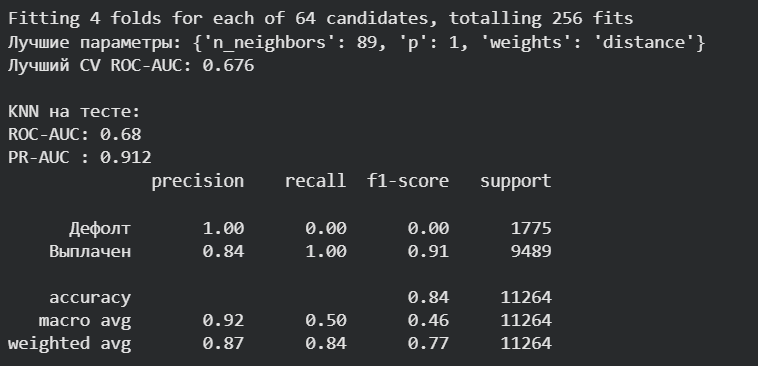

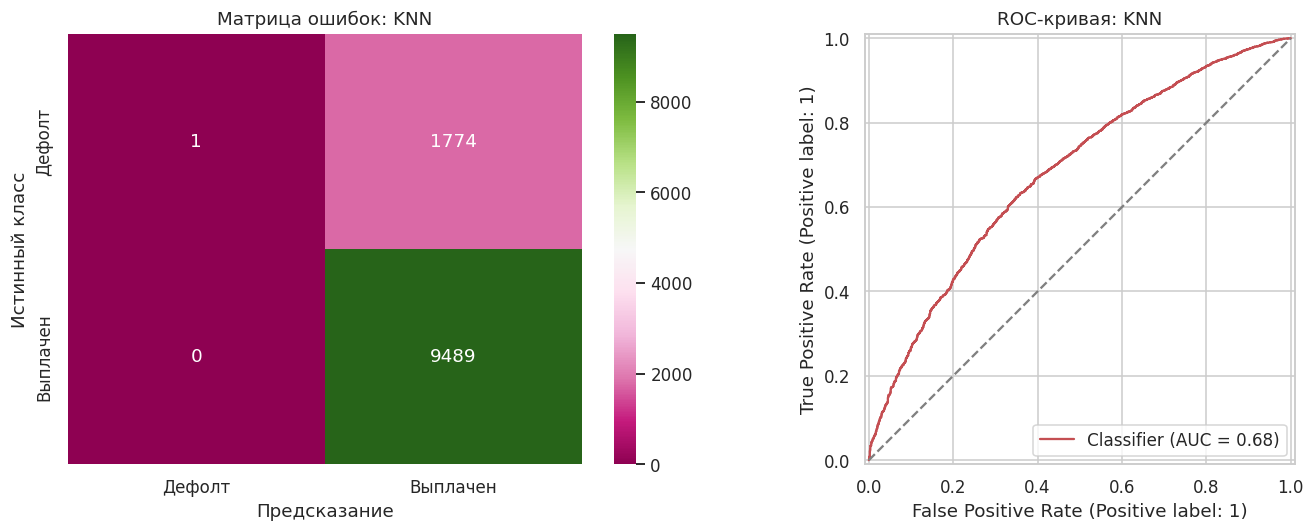

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(y_test_ksl, pred_knn)
sns.heatmap(cm, annot=True, fmt="d", cmap="PiYG", ax=ax[0], xticklabels=["Дефолт", "Выплачен"], yticklabels=["Дефолт", "Выплачен"])
ax[0].set_xlabel("Предсказание"); ax[0].set_ylabel("Истинный класс")
ax[0].set_title("Матрица ошибок: KNN")
RocCurveDisplay.from_predictions(y_test_ksl, proba_knn, ax=ax[1], color="#C44E52")
ax[1].plot([0, 1], [0, 1], "--", color="grey")
ax[1].set_title("ROC-кривая: KNN")
plt.show()

Вывод по KNN: модель получилась слабым бейзлайном. ROC-AUC ≈ 0.68 — заёмщиков по риску она различает чуть лучше случайного, но на пороге 0.5 из-за дисбаланса (84/16) присваивает почти всем класс «выплачен» и не выявляет дефолты (recall дефолтов ≈ 0). Высокие accuracy 0.84 и F1 0.91 здесь обманчивы — их даёт само большинство, а не качество модели. Причины слабости: отсутствие у KNN балансировки классов и проклятие размерности (113 признаков). Ожидаем, что ансамбли (случайный лес, бустинг) покажут заметно лучший результат.

# Случайный лес

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, precision_score

param_grid = {"n_estimators": [200, 300, 500], "max_depth": [10, 20, None], "min_samples_leaf": [1, 5, 20], "max_features": ["sqrt", 0.5],}
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=67)

search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=67, n_jobs=-1),
    param_grid, n_iter=12, scoring="roc_auc", cv=cv, random_state=67, n_jobs=-1, verbose=1)
search.fit(X_train_dlb, y_train_dlb)
print("Лучшие параметры:", search.best_params_)
print("Лучший CV ROC-AUC:", round(search.best_score_, 3))

rf = search.best_estimator_
proba_rf = rf.predict_proba(X_test_dlb)[:, 1]
pred_rf  = rf.predict(X_test_dlb)
print("Random Forest на тесте:")
print("ROC-AUC:", round(roc_auc_score(y_test_dlb, proba_rf), 3))
print("PR-AUC :", round(average_precision_score(y_test_dlb, proba_rf), 3))
print(classification_report(y_test_dlb, pred_rf, target_names=["Дефолт", "Выплачен"]))

Fitting 4 folds for each of 12 candidates, totalling 48 fits
Лучшие параметры: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': None}
Лучший CV ROC-AUC: 0.723

Random Forest на тесте:
ROC-AUC: 0.712
PR-AUC : 0.925
              precision    recall  f1-score   support

      Дефолт       0.33      0.38      0.35      1775
    Выплачен       0.88      0.86      0.87      9489

    accuracy                           0.78     11264
   macro avg       0.60      0.62      0.61     11264
weighted avg       0.79      0.78      0.79     11264



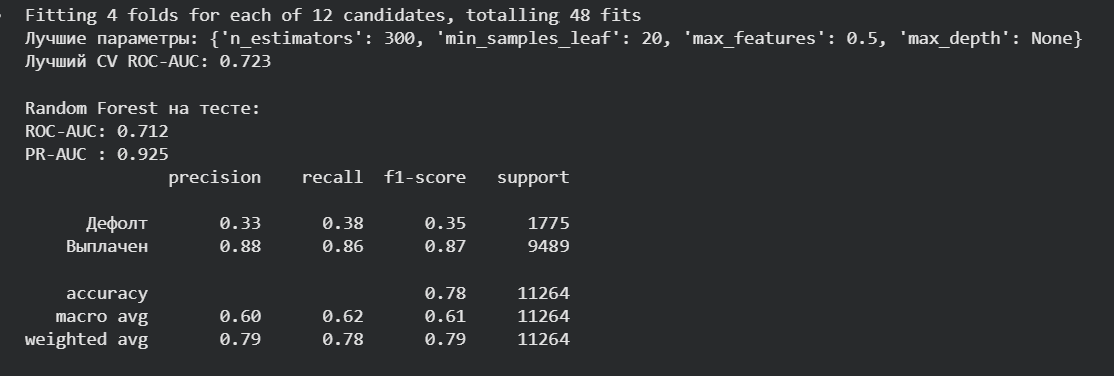

In [ ]:
print("Порог | recall дефолтов | precision дефолтов")
for thr in [0.5, 0.6, 0.7, 0.8]:
    pred = (proba_rf >= thr).astype(int)
    rec  = recall_score(y_test_dlb, pred, pos_label=0)
    prec = precision_score(y_test_dlb, pred, pos_label=0)
    print(f"{thr:>4} | {rec:>15.2f} | {prec:.2f}")

Порог | recall дефолтов | precision дефолтов
 0.5 |            0.38 | 0.33
 0.6 |            0.60 | 0.27
 0.7 |            0.82 | 0.22
 0.8 |            0.94 | 0.19


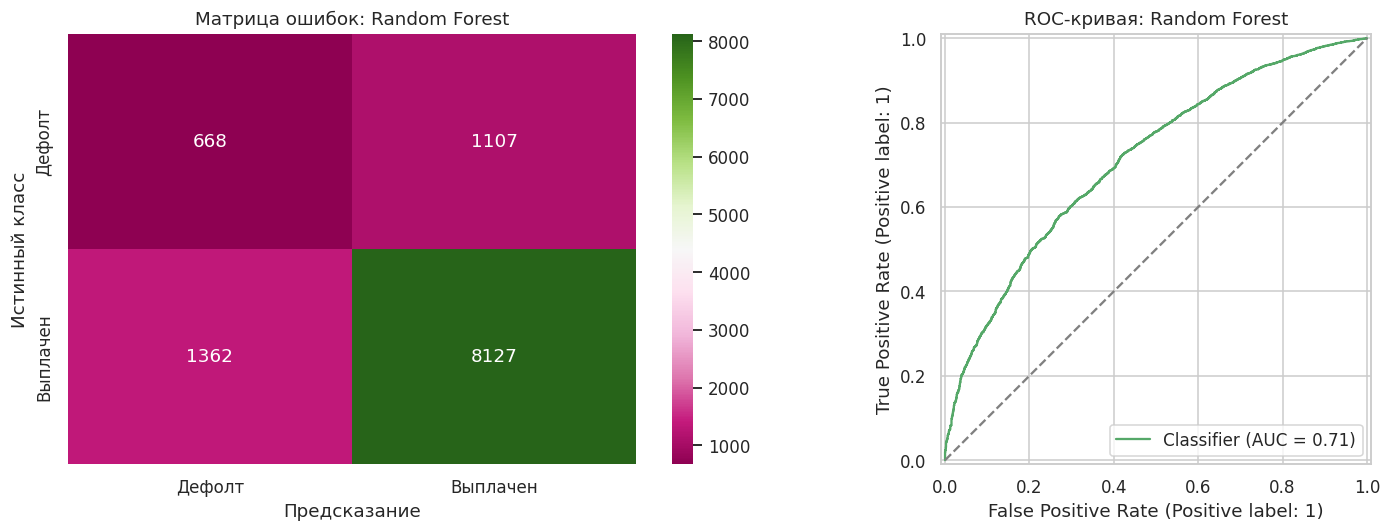

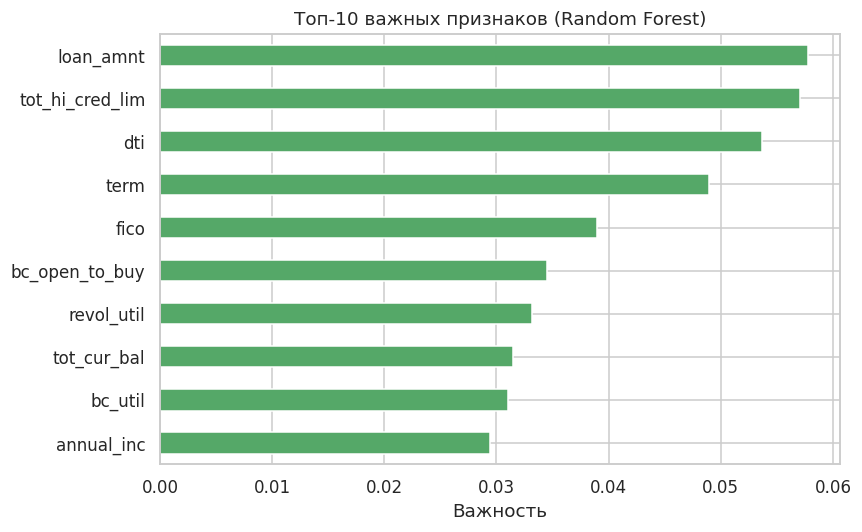

In [ ]:
cm = confusion_matrix(y_test_ksl, pred_knn)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="PiYG",
            xticklabels=["Дефолт", "Выплачен"], yticklabels=["Дефолт", "Выплачен"])
plt.xlabel("Предсказание")
plt.ylabel("Истинный класс")
plt.title("Матрица ошибок: KNN")
plt.show()

fpr, tpr, _ = roc_curve(y_test_ksl, proba_knn)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#55A868", label=f"KNN (AUC = {roc_auc_score(y_test_ksl, proba_knn):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC-кривая: KNN")
plt.show()

модель показала ROC-AUC 0.71 и на пороге 0.5 выявляет ~38% дефолтов (recall класса 0 = 0.38) — это полноценный рабочий классификатор, в отличие от KNN, который дефолты не находил вовсе. Accuracy снизилась до 0.78, но это осознанный и правильный для кредитного скоринга размен: модель жертвует общей точностью ради выявления рисковых заёмщиков. Подбор гиперпараметров (min_samples_leaf=20, max_features=0.5) сделал лес устойчивее к переобучению (CV 0.723 ≈ тест 0.712). Порог можно сдвигать под бизнес-задачу: выше порог — больше пойманных дефолтов ценой ложных отказов.

# Дерево

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import cross_validate, cross_val_score

In [ ]:
tree = DecisionTreeClassifier(max_depth=9, class_weight='balanced')
tree.fit(X_train_dlb, y_train_dlb)
print(f'roc-auc {roc_auc_score(y_test_dlb, tree.predict(X_test_dlb))} f1 {f1_score(y_test_dlb, tree.predict(X_test_dlb))}')

roc-auc 0.5997548829704966 f1 0.7435630848266161


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

max_depth = [5, 7, 10, 15]
min_samples_leaf = [3, 5, 10, 20]
min_samples_split = [2, 5, 10]

best_score = 0

for i in max_depth:
    for j in min_samples_leaf:
        for k in min_samples_split:
          tree = DecisionTreeClassifier(max_depth=i, min_samples_leaf=j, min_samples_split=k, class_weight='balanced', random_state=42)
          scores = cross_val_score(tree, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1).mean()

          print(f'depth {i} leaf {j} split {k} auc-roc {scores}')

          if scores > best_score:
            best_score = scores
            max_depth_best = i
            min_samples_leaf_best = j
            min_samples_split_best = k

print(f'auc-roc {best_score} max_depth {max_depth_best} min_samples_leaf {min_samples_leaf_best} min_samples_split {min_samples_split_best}')

depth 5 leaf 3 split 2 auc-roc 0.6635232450143246
depth 5 leaf 3 split 5 auc-roc 0.6635232450143246
depth 5 leaf 3 split 10 auc-roc 0.6635232450143246
depth 5 leaf 5 split 2 auc-roc 0.6635270297412394
depth 5 leaf 5 split 5 auc-roc 0.6635270297412394
depth 5 leaf 5 split 10 auc-roc 0.6635270297412394
depth 5 leaf 10 split 2 auc-roc 0.6640515838207195
depth 5 leaf 10 split 5 auc-roc 0.6640515838207195
depth 5 leaf 10 split 10 auc-roc 0.6640515838207195
depth 5 leaf 20 split 2 auc-roc 0.6646589619314395
depth 5 leaf 20 split 5 auc-roc 0.6646589619314395
depth 5 leaf 20 split 10 auc-roc 0.6646589619314395
depth 7 leaf 3 split 2 auc-roc 0.6541912638112063
depth 7 leaf 3 split 5 auc-roc 0.6541912638112063
depth 7 leaf 3 split 10 auc-roc 0.6542145590143453
depth 7 leaf 5 split 2 auc-roc 0.6539017003879559
depth 7 leaf 5 split 5 auc-roc 0.6539017003879559
depth 7 leaf 5 split 10 auc-roc 0.6539017003879559
depth 7 leaf 10 split 2 auc-roc 0.6554879438257786
depth 7 leaf 10 split 5 auc-roc 0.655

In [ ]:
tree1 = DecisionTreeClassifier(max_depth=max_depth_best, min_samples_leaf=min_samples_leaf_best, min_samples_split=min_samples_split_best, class_weight='balanced', random_state=13)
tree1.fit(X_train_dlb, y_train_dlb)

DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                       min_samples_leaf=20, random_state=13)

In [ ]:
print(f'roc-auc {roc_auc_score(y_test_dlb, tree1.predict(X_test_dlb))} f1 {f1_score(y_test_dlb, tree1.predict(X_test_dlb))}')

roc-auc 0.6077416549036022 f1 0.6867885253366292


# Бустинг

Все образцы нахождения гиперпараметров взяты с аналогии с ДЗ7

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import cross_validate

grad_bust = GradientBoostingClassifier(random_state=42)
grad_bust.fit(X_train_dlb, y_train_dlb)

GradientBoostingClassifier(random_state=42)

In [ ]:
print(f'f1: {f1_score(y_test_dlb, grad_bust.predict(X_test_dlb))}')
print(f'auc-roc: {roc_auc_score(y_test_dlb, grad_bust.predict_proba(X_test_dlb)[:, 1])}')

f1: 0.9149679673849738
auc-roc: 0.7229443135788066


Подбираем лернинг рейт и количество деревьев

In [ ]:
lrs = [0.01, 0.05, 0.1, 0.2, 0.3]
n_estimators = [50, 100, 150, 200, 300]

best_score = 0

for i in lrs:
    for j in n_estimators:
        gb = GradientBoostingClassifier(learning_rate=i, n_estimators=j, random_state=42)
        scores = cross_validate(gb, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'lr {i}, n_est {j} auc-roc {scores}')

        if scores > best_score:
            best_score = scores
            lr_best = i
            nest_best = j

print(f'lr_best {lr_best} nest_best {nest_best} auc-roc {best_score}')

lr 0.01, n_est 50 auc-roc 0.6790687537816869 (64.8с)
lr 0.01, n_est 100 auc-roc 0.6930594717157769 (104.8с)
lr 0.01, n_est 150 auc-roc 0.7017553750772695 (162.4с)
lr 0.01, n_est 200 auc-roc 0.7068627428152451 (207.2с)
lr 0.01, n_est 300 auc-roc 0.7141008340525278 (309.5с)
lr 0.05, n_est 50 auc-roc 0.711241553292973 (50.0с)
lr 0.05, n_est 100 auc-roc 0.7208153659257127 (102.0с)
lr 0.05, n_est 150 auc-roc 0.7254698563986887 (150.1с)
lr 0.05, n_est 200 auc-roc 0.7280542184159634 (198.6с)
lr 0.05, n_est 300 auc-roc 0.7307692445593991 (296.5с)
lr 0.1, n_est 50 auc-roc 0.7207003328548156 (50.4с)
lr 0.1, n_est 100 auc-roc 0.7274437298467141 (104.1с)
lr 0.1, n_est 150 auc-roc 0.7306011528266879 (147.6с)
lr 0.1, n_est 200 auc-roc 0.7321656359776711 (197.3с)
lr 0.1, n_est 300 auc-roc 0.7324969617332515 (296.2с)
lr 0.2, n_est 50 auc-roc 0.7247907126820413 (49.8с)
lr 0.2, n_est 100 auc-roc 0.7286113662052486 (98.5с)
lr 0.2, n_est 150 auc-roc 0.7292498809318646 (147.9с)
lr 0.2, n_est 200 auc-roc 0.

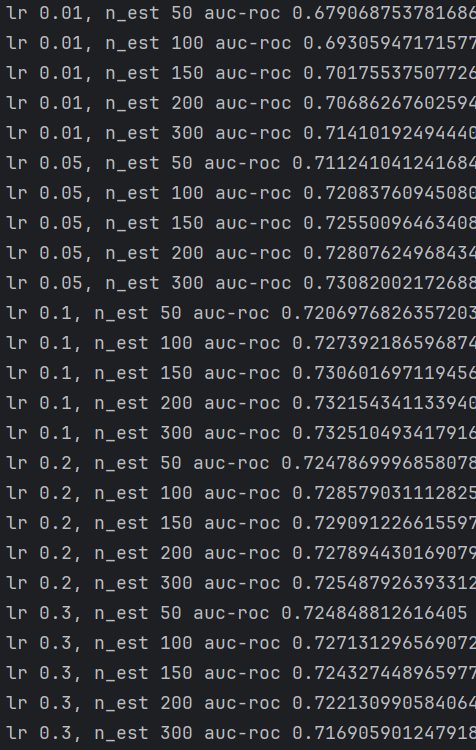

image.png

In [ ]:
max_depth = [3, 5, 7, 9, 11]
min_samples_split = [2, 5, 10, 20, 50]

best_score = 0

for i in max_depth:
    for j in min_samples_split:
        gb = GradientBoostingClassifier(
            learning_rate=lr_best,
            n_estimators=nest_best,
            max_depth=i,
            min_samples_split=j,
            random_state=42
        )
        scores = cross_validate(gb, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'depth {i}, split {j} auc-roc {scores}')

        if scores > best_score:
            best_score = scores
            depth_best = i
            split_best = j

print(f'depth_best {depth_best} split_best {split_best} auc-roc {best_score:.4f}')

In [ ]:
depth_best, split_best, lr_best, nest_best = 3, 50, 0.1, 300

Вот результат:

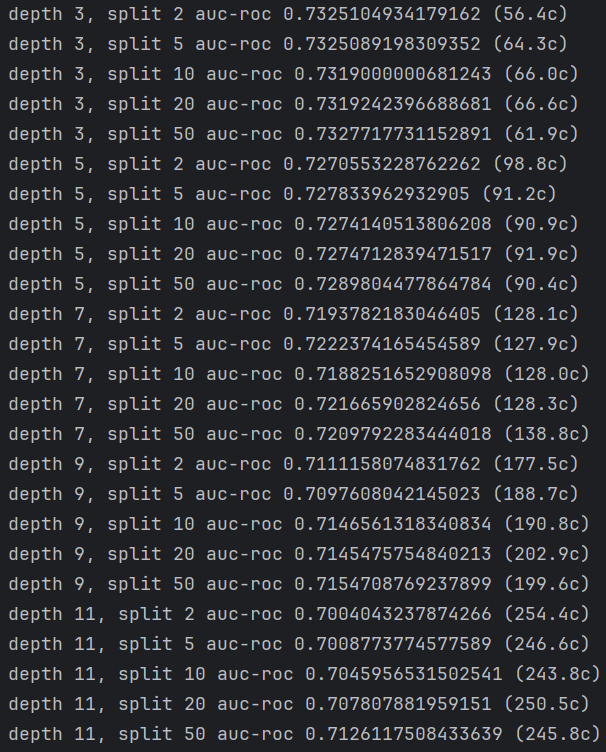

Итоговые гиперпараметры:

image.png

Подбираем ещё один гиперпараметр:

In [ ]:
subsamples = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

best_score = 0
subsample_best = None

for i in subsamples:
    gb = GradientBoostingClassifier(learning_rate=lr_best, n_estimators=nest_best, max_depth=depth_best, min_samples_split=split_best, subsample=i, random_state=42)
    scores = cross_validate(gb, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
    print(f'subsample {i} auc-roc {scores}')

    if scores > best_score:
        best_score = scores
        subsample_best = i

print(f'subsample_best {subsample_best} auc-roc {best_score}')

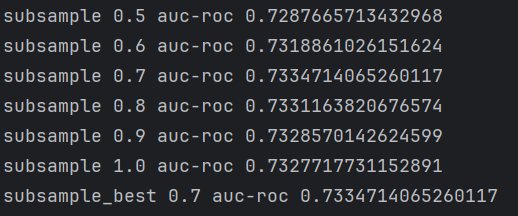

Теперь обучаем бустинг с лучшими гиперпараметрами и смотрим на тест:

In [ ]:
gb_final = GradientBoostingClassifier(learning_rate=lr_best, n_estimators=nest_best, max_depth=depth_best, min_samples_split=split_best, subsample=subsample_best, random_state=42)
gb_final.fit(X_train_dlb, y_train_dlb)

print(f'f1 {f1_score(y_test_dlb, gb_final.predict(X_test_dlb))}')
print(f'auc-roc {roc_auc_score(y_test_dlb, gb_final.predict_proba(X_test_dlb)[:, 1])}')

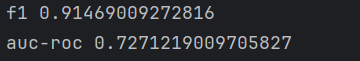

Давайте проверим особые реализации GB: XGBoost, CatBoost, LightGBM

Начнём с XGBoost, подбираем гиперпараметры:

In [ ]:
from xgboost import XGBClassifier

lrs = [0.01, 0.05, 0.1, 0.2, 0.3]
n_estimators = [50, 100, 150, 200, 300]

best_score = 0

for i in lrs:
    for j in n_estimators:
        model = XGBClassifier(learning_rate=i, n_estimators=j, random_state=42, eval_metric='logloss')
        scores = cross_validate(model, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'lr {i}, n_est {j} auc-roc {scores}')
        if scores > best_score:
            best_score = scores
            lr_best = i
            nest_best = j

print(f'lr_best {lr_best}, nest_best {nest_best}, auc-roc {best_score}')

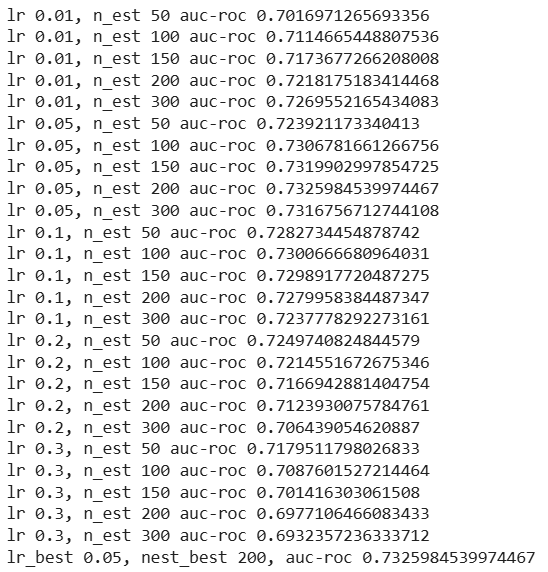

In [ ]:
max_depth = [3, 5, 7, 9]
min_child_weight = [1, 3, 5, 7]

best_score = 0

for i in max_depth:
    for j in min_child_weight:
        model = XGBClassifier(learning_rate=lr_best, n_estimators=nest_best, max_depth=i, min_child_weight=j, random_state=42, eval_metric='logloss')
        scores = cross_validate(model, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'depth {i}, weight {j} auc-roc {scores}')
        if scores > best_score:
            best_score = scores
            depth_best = i
            weight_best = j

print(f'depth_best {depth_best} weight_best {weight_best} auc-roc {best_score}')

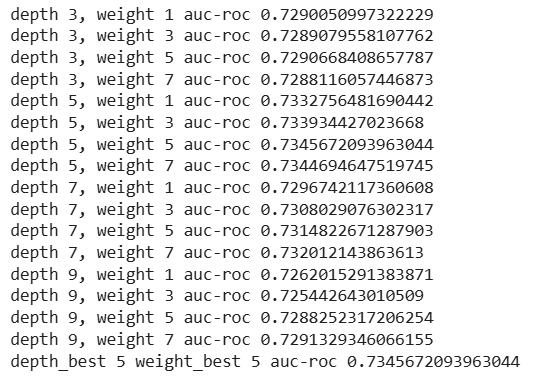

In [ ]:
xgb_final = XGBClassifier(learning_rate=lr_best, n_estimators=nest_best, max_depth=depth_best, min_child_weight=weight_best, random_state=42,eval_metric='logloss')
xgb_final.fit(X_train_dlb, y_train_dlb)
print(f'f1 {f1_score(y_test_dlb, xgb_final.predict(X_test_dlb))}')
print(f'auc-roc {roc_auc_score(y_test_dlb, xgb_final.predict_proba(X_test_dlb)[:, 1])}')

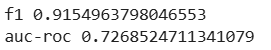

Теперь пришло время CatBoost:

In [ ]:
!pip install --upgrade catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.7 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier

lrs = [0.01, 0.05, 0.1, 0.2, 0.3]
iterations = [50, 100, 150, 200, 300]

best_score = 0

for i in lrs:
    for j in iterations:
        model = CatBoostClassifier(learning_rate=i, iterations=j, random_seed=42)
        scores = cross_validate(model, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'lr {i}, it {j} auc-roc {scores}')
        if scores > best_score:
            best_score = scores
            lr_cat_best = i
            it_best = j

print(f'lr_cat_best {lr_cat_best} it_best {it_best} auc-roc {best_score}')

lr 0.01, it 50 auc-roc 0.6908148907745254
lr 0.01, it 100 auc-roc 0.7008843074381819
lr 0.01, it 150 auc-roc 0.7087296838725416
lr 0.01, it 200 auc-roc 0.7140038456852097
lr 0.01, it 300 auc-roc 0.7197611207558893
lr 0.05, it 50 auc-roc 0.7152156991909856
lr 0.05, it 100 auc-roc 0.7243046549489569
lr 0.05, it 150 auc-roc 0.7282089892449495
lr 0.05, it 200 auc-roc 0.7307353647219245
lr 0.05, it 300 auc-roc 0.7336720680730435
lr 0.1, it 50 auc-roc 0.7235908107043795
lr 0.1, it 100 auc-roc 0.7288770704332147
lr 0.1, it 150 auc-roc 0.7313453844122799
lr 0.1, it 200 auc-roc 0.7326890857384544
lr 0.1, it 300 auc-roc 0.7321974766526947
lr 0.2, it 50 auc-roc 0.7240500288342613
lr 0.2, it 100 auc-roc 0.7282685484126744
lr 0.2, it 150 auc-roc 0.7252835440027985
lr 0.2, it 200 auc-roc 0.7230633901237488
lr 0.2, it 300 auc-roc 0.7185619624956129
lr 0.3, it 50 auc-roc 0.7228599568708534
lr 0.3, it 100 auc-roc 0.7209359297374826
lr 0.3, it 150 auc-roc 0.7161025328267882
lr 0.3, it 200 auc-roc 0.7127

In [ ]:
depths = [3, 5, 7, 9]

best_score = 0

for i in depths:
    model = CatBoostClassifier(learning_rate=lr_cat_best, iterations=it_best, depth=i, random_seed=42)
    scores = cross_validate(model, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
    print(f'depth {i} auc-roc {scores}')
    if scores > best_score:
        best_score = scores
        depth_cat_best = i

print(f'depth_cat_best {depth_cat_best} auc-roc {best_score}')

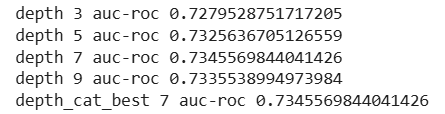

In [ ]:
cat_final = CatBoostClassifier(learning_rate=lr_cat_best, iterations=it_best, depth=depth_cat_best, random_seed=42)
cat_final.fit(X_train_dlb, y_train_dlb)

print(f'f1 {f1_score(y_test_dlb, cat_final.predict(X_test_dlb))}')
print(f'auc-roc {roc_auc_score(y_test_dlb, cat_final.predict_proba(X_test_dlb)[:, 1])}')

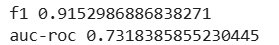

Дошла очередь и до LightGBM

In [ ]:
from lightgbm import LGBMClassifier

lrs = [0.01, 0.05, 0.1, 0.2, 0.3]
n_estimators = [50, 100, 150, 200, 300]

best_score = 0

for i in lrs:
    for j in n_estimators:
        model = LGBMClassifier(learning_rate=i, n_estimators=j, random_state=42)
        scores = cross_validate(model, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'lr {i}, n_est {j} auc-roc {scores}')
        if scores > best_score:
            best_score = scores
            lr_lgb_best = i
            nest_lgb_best = j

print(f'lr_lgb_best {lr_lgb_best} nest_lgb_best {nest_lgb_best} auc-roc {best_score}')

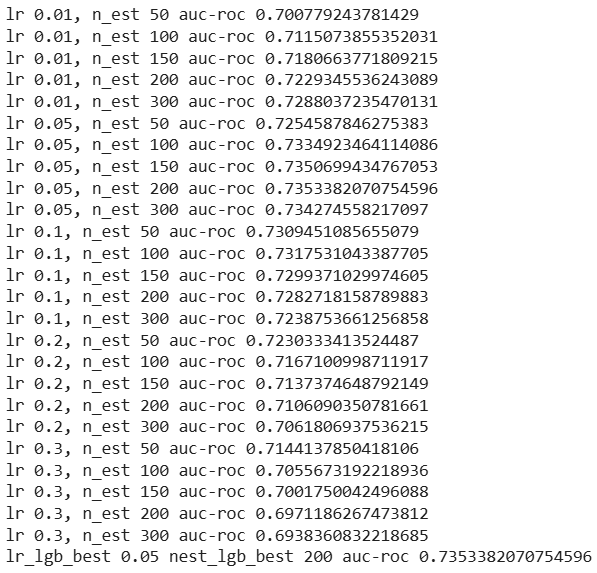

In [ ]:
num_leaves = [15, 31, 63, 127]
max_depth = [3, 5, 7, 9]

best_score = 0

for i in num_leaves:
    for j in max_depth:
        model = LGBMClassifier(learning_rate=lr_lgb_best, n_estimators=nest_lgb_best, num_leaves=i, max_depth=j, random_state=42)
        scores = cross_validate(model, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'leaves {i}, depth {j} auc-roc {scores}')
        if scores > best_score:
            best_score = scores
            leaves_best = i
            depth_lgb_best = j

print(f'leaves_best {leaves_best} depth_lgb_best {depth_lgb_best} auc-roc {best_score}')

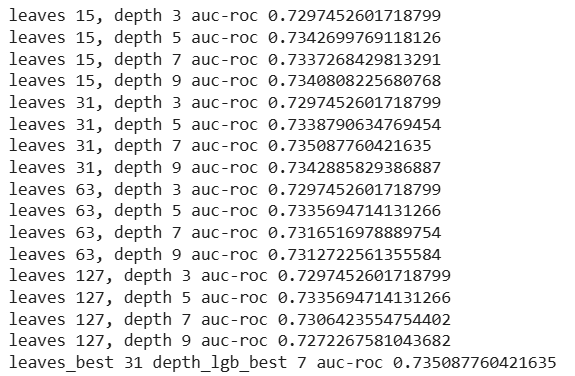

In [ ]:
subsamples = [0.6, 0.7, 0.8, 0.9, 1.0]
colsample = [0.6, 0.7, 0.8, 0.9, 1.0]

best_score = 0

for i in subsamples:
    for j in colsample:
        model = LGBMClassifier(learning_rate=lr_lgb_best, n_estimators=nest_lgb_best, num_leaves=leaves_best, max_depth=depth_lgb_best, subsample=i, colsample_bytree=j, random_state=42)
        scores = cross_validate(model, X_train_dlb, y_train_dlb, cv=3, scoring='roc_auc', n_jobs=-1)['test_score'].mean()
        print(f'sub {i}, col {j} auc-roc {scores}')
        if scores > best_score:
            best_score = scores
            sub_best = i
            col_best = j

print(f'sub_best {sub_best} col_best {col_best} auc-roc {best_score}')

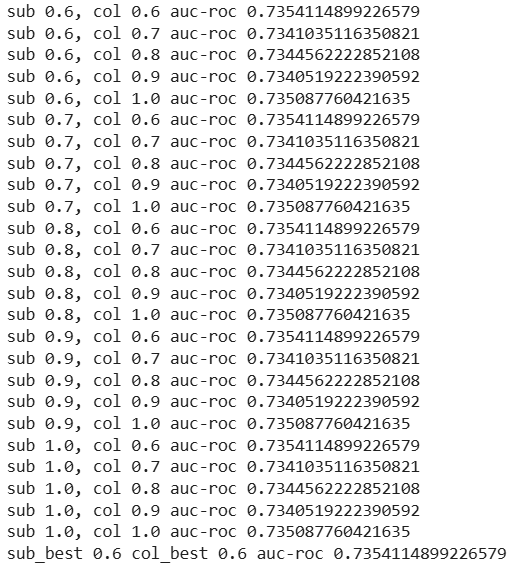

In [ ]:
lgb_final = LGBMClassifier(learning_rate=lr_lgb_best, n_estimators=nest_lgb_best, num_leaves=leaves_best, max_depth=depth_lgb_best, subsample=sub_best, colsample_bytree=col_best, random_state=42)
lgb_final.fit(X_train_dlb, y_train_dlb)

print(f'f1 {f1_score(y_test_dlb, lgb_final.predict(X_test_dlb))}')
print(f'auc-roc {roc_auc_score(y_test_dlb, lgb_final.predict_proba(X_test_dlb)[:, 1])}')

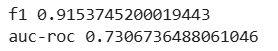

##Сводная таблица

In [ ]:
results_clf = pd.DataFrame({"model": ["LogReg", "kNN", "Decision Tree", "Random Forest","GradBoost", "XGBoost", "CatBoost", "LightGBM"],

    "ROC_AUC": [roc_auc_score(y_test_ksl, y_proba),
                roc_auc_score(y_test_ksl, proba_knn),
                roc_auc_score(y_test_dlb, tree1.predict_proba(X_test_dlb)[:, 1]),
                roc_auc_score(y_test_dlb, proba_rf),
                roc_auc_score(y_test_dlb, gb_final.predict_proba(X_test_dlb)[:, 1]),
                roc_auc_score(y_test_dlb, xgb_final.predict_proba(X_test_dlb)[:, 1]),
                roc_auc_score(y_test_dlb, cat_final.predict_proba(X_test_dlb)[:, 1]),
                roc_auc_score(y_test_dlb, lgb_final.predict_proba(X_test_dlb)[:, 1])],

    "F1": [f1_score(y_test_ksl, y_pred),
           f1_score(y_test_ksl, pred_knn),
           f1_score(y_test_dlb, tree1.predict(X_test_dlb)),
           f1_score(y_test_dlb, pred_rf),
           f1_score(y_test_dlb, gb_final.predict(X_test_dlb)),
           f1_score(y_test_dlb, xgb_final.predict(X_test_dlb)),
           f1_score(y_test_dlb, cat_final.predict(X_test_dlb)),
           f1_score(y_test_dlb, lgb_final.predict(X_test_dlb))]}).sort_values("ROC_AUC", ascending=False)

results_clf

In [ ]:
results_clf.plot(x="model", y="ROC_AUC", kind="bar", figsize=(10, 5), color="lightblue")
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC по моделям")
plt.xticks(rotation=20)
plt.show()